# Định giá (module phụ)

Đọc `results/valuation_metrics.json`: model XGBoost dự đoán giá/m² của tin bán, biến thể `tabular` (đặc trưng cấu trúc) và
`full` (thêm vector mô tả nén PCA), so với baseline trung vị phường. Sinh bằng `python scripts/vre_pipeline.py price --variant tabular|full`.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

# Gốc dữ liệu: VRE_DATA_ROOT (vre_env.ps1 đặt về checkout chính) hoặc gốc repo (CI, chạy từ notebooks/).
_here = Path.cwd().resolve()
DATA_ROOT = Path(os.environ.get("VRE_DATA_ROOT") or (_here.parent if _here.name == "notebooks" else _here))
RESULTS = DATA_ROOT / "results"
pd.set_option("display.max_colwidth", 120)


def load(name):
    """Đọc results/<name>; trả None nếu file chưa được sinh."""
    path = RESULTS / name
    return json.loads(path.read_text(encoding="utf-8")) if path.exists() else None


def md(text):
    display(Markdown(text))


def missing(name, command):
    md(f"> **chưa có** — `results/{name}` chưa được sinh. Sinh bằng `{command}` rồi chạy lại notebook.")


def num(x):
    """Số nguyên kiểu Việt Nam: 2.537.920."""
    return f"{int(x):,}".replace(",", ".")


def dec(x, digits=2):
    """Số thực kiểu Việt Nam: 0,71."""
    return f"{x:,.{digits}f}".replace(",", "_").replace(".", ",").replace("_", ".")


def pct(x, digits=1):
    """Tỉ lệ 0..1 → phần trăm."""
    return dec(x * 100, digits) + "%"


def provenance(obj):
    if isinstance(obj, dict) and "generated_at" in obj:
        md(f"*Nguồn: sinh lúc `{obj['generated_at']}`, commit `{obj.get('git_sha')}`.*")


md("Đọc `results/` dưới " + ("`VRE_DATA_ROOT`." if os.environ.get("VRE_DATA_ROOT") else "gốc repo."))

Đọc `results/` dưới `VRE_DATA_ROOT`.

## Chia tập và phạm vi

In [2]:
val = load("valuation_metrics.json")
if val is None:
    missing("valuation_metrics.json", "python scripts/vre_pipeline.py price --variant tabular")
else:
    provenance(val)
    sp, rent = val["split"], val["rent_model"]
    md(
        f"Train: tháng `{sp['train_months'][0]}` → `{sp['train_months'][-1]}`; test: `{sp['test_months'][0]}` → "
        f"`{sp['test_months'][-1]}` (chia theo thời gian, không trộn). Model thuê: "
        + ("đã huấn luyện." if rent["trained"] else f"không huấn luyện ({num(rent['n_rent'])} tin thuê; lý do: `{rent['reason']}`).")
    )

*Nguồn: sinh lúc `2026-10-15T14:00:24Z`, commit `996d20a`.*

Train: tháng `2025-06` → `2026-01`; test: `2026-02` → `2026-03` (chia theo thời gian, không trộn). Model thuê: không huấn luyện (253 tin thuê; lý do: `n_rent=253 < rent_min_rows=20000`).

## So sánh biến thể

In [3]:
if val is not None:
    variants = {k: v for k, v in val["variants"].items() if v is not None}
    cmp_df = pd.DataFrame(
        {k: {"n_train": v["n_train"], "n_test": v["n_test"], "mae_mil_m2": v["mae_mil_m2"], "mape": v["mape"], "r2": v["r2"],
             "train_seconds": v["train_seconds"]} for k, v in variants.items()}
    ).T
    display(cmp_df)
    if val["variants"].get("full") is None:
        missing("valuation_metrics.json (variants.full)", "python scripts/vre_pipeline.py price --variant full")
    base = val["variants"]["baseline_ward_median"]
    for name in ("tabular", "full"):
        v = val["variants"].get(name)
        if v is None:
            continue
        verb = "giảm" if v["mape"] < base["mape"] else "không giảm"
        md(
            f"`{name}`: MAPE {pct(v['mape'])} so với baseline phường {pct(base['mape'])} ({verb}); "
            f"MAE {dec(v['mae_mil_m2'], 1)} so với {dec(base['mae_mil_m2'], 1)} triệu/m²; R² {dec(v['r2'], 3)} so với {dec(base['r2'], 3)}."
        )
    if val["variants"].get("full") is not None:
        t, f = val["variants"]["tabular"], val["variants"]["full"]
        md(f"Thêm vector mô tả (`full`) đổi MAPE từ {pct(t['mape'])} thành {pct(f['mape'])} trên cùng tập test.")

,n_train,n_test,mae_mil_m2,mape,r2,train_seconds
tabular,1865193.0,395910.0,32.624495,0.240247,0.727003,3436.9
full,1865193.0,395910.0,24.049848,0.190938,0.844781,1758.0
baseline_ward_median,1865193.0,395910.0,50.613928,0.460424,0.476394,0.0


`tabular`: MAPE 24,0% so với baseline phường 46,0% (giảm); MAE 32,6 so với 50,6 triệu/m²; R² 0,727 so với 0,476.

`full`: MAPE 19,1% so với baseline phường 46,0% (giảm); MAE 24,0 so với 50,6 triệu/m²; R² 0,845 so với 0,476.

Thêm vector mô tả (`full`) đổi MAPE từ 24,0% thành 19,1% trên cùng tập test.

## Theo loại bất động sản

,tabular,full,baseline_ward_median
property_type,,,
Biệt thự/Nhà liền kề,0.200265,0.175829,0.369527
Căn hộ chung cư,0.161572,0.126173,0.666149
Nhà,0.243191,0.184916,0.324393
Shophouse,0.250854,0.224080,0.456840
Đất,0.330025,0.272810,0.538061


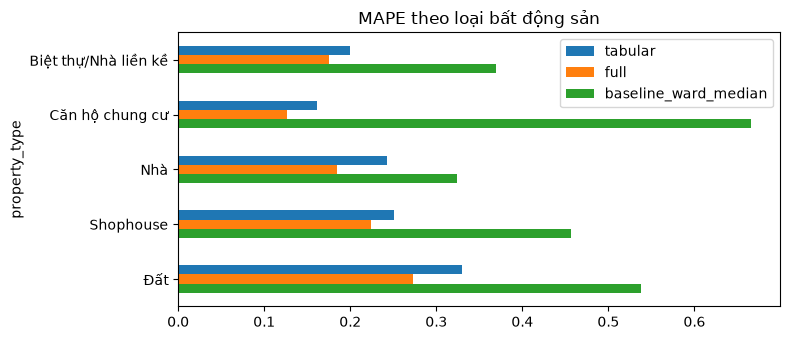

In [4]:
if val is not None:
    parts = []
    for name, v in variants.items():
        df = pd.DataFrame(v["by_property_type"])
        if not df.empty:
            parts.append(df.set_index("property_type")["mape"].rename(name))
    by_type = pd.concat(parts, axis=1) if parts else pd.DataFrame()
    display(by_type)
    if not by_type.empty:
        by_type.plot.barh(figsize=(8, 3.5), title="MAPE theo loại bất động sản").invert_yaxis()
        plt.tight_layout()
        plt.show()

## Theo tỉnh (nhiều tin nhất)

In [5]:
if val is not None:
    parts = []
    for name, v in variants.items():
        df = pd.DataFrame(v["by_province_top10"])
        if not df.empty:
            parts.append(df.set_index("province")["mape"].rename(name))
    display(pd.concat(parts, axis=1) if parts else pd.DataFrame())

,tabular,full,baseline_ward_median
province,,,
Hồ Chí Minh,0.230105,0.176578,0.411671
Hà Nội,0.228730,0.160687,0.530166
Đà Nẵng,0.191917,0.165427,0.293008
Bình Dương,0.178595,0.233025,0.321064
Khánh Hòa,0.261045,0.226041,0.490071
Hải Phòng,0.226208,0.196465,0.448184
Đồng Nai,0.302607,0.263861,0.584233
Hưng Yên,0.147875,0.123150,0.389115
Long An,0.362701,0.294079,0.561695


## Đặc trưng quan trọng (SHAP)

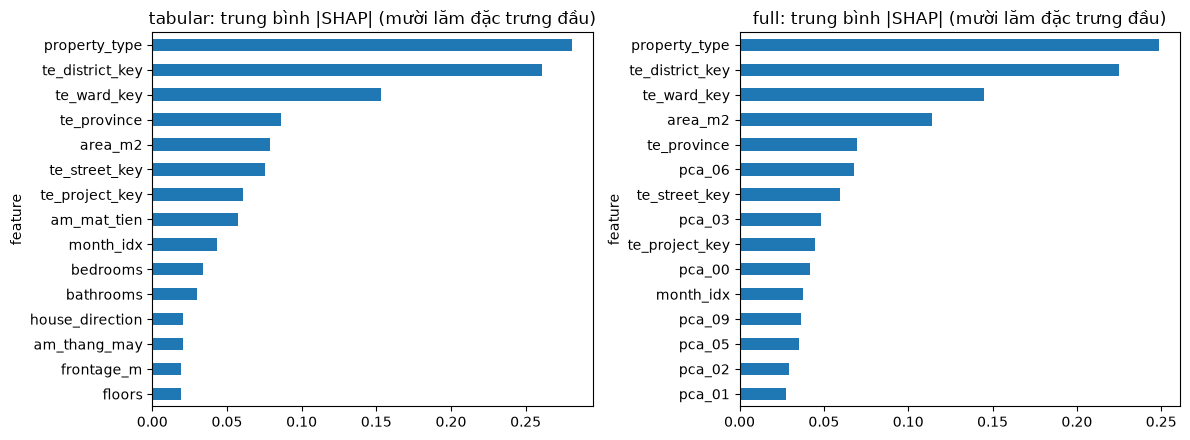

In [6]:
if val is not None:
    shap_variants = {k: v for k, v in variants.items() if v["shap_top"]}
if val is not None and shap_variants:
    fig, axes = plt.subplots(1, len(shap_variants), figsize=(6 * len(shap_variants), 4.5), squeeze=False)
    for ax, (name, v) in zip(axes[0], shap_variants.items(), strict=True):
        s = pd.DataFrame(v["shap_top"]).head(15).set_index("feature")["mean_abs_contribution"]
        s.plot.barh(ax=ax, title=f"{name}: trung bình |SHAP| (mười lăm đặc trưng đầu)")
        ax.invert_yaxis()
    fig.tight_layout()
    plt.show()